# Phase 3 — Window-Length Sensitivity Analysis

Implements Chapter 3, Section 3.4 and Chapter 4, Section 4.5 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"*.

Window length — the number of observations treated as "recent" for drift monitoring and
feature reassessment — is determined empirically here, using the best static model
identified in Phase 2, rather than assumed.

This analysis uses two separate sweeps, run over different data:

- **Feature-stability sweep** (model-free): features are ranked by windowed correlation
  with the target (Chapter 3, Section 3.6.3), and stability between consecutive windows is
  measured. Since this does not use the model's predictions at all, it is run over the
  **full cleaned dataset** (~50,000 rows) across a wide range of window sizes, so a genuine
  stability plateau can be identified rather than being limited by test-set size.
- **Predictive-accuracy sweep**: the best model predicts within each window of the
  **held-out test stream only** (~10,000 rows), over the same candidate sizes used in the
  stability sweep up to a practical limit, to check accuracy does not degrade at the chosen
  window size.

**Output:**
- `results/tables/phase3_stability_sweep.csv` — stability metrics per window size (full dataset)
- `results/tables/phase3_accuracy_sweep.csv` — accuracy metrics per window size (test set)
- `results/tables/phase3_per_window_detail.csv` — per-window detail for the chosen size
- `results/figures/phase3_window_sensitivity.png` — trade-off plot across window sizes
- `results/tables/phase3_artifacts.json` — the chosen window length, consumed by Phases 4–9

In [1]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/dissertation-project


In [2]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_utils as du
import models as mdl
import metrics as mt

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load Phase 2 artefacts and both datasets

The stability sweep uses the full cleaned dataset (model-free, so no leakage concern); the accuracy sweep uses the held-out test stream only, consistent with Phase 2.

In [4]:
artifacts_p2 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase2_artifacts.json'))
best_model_name = artifacts_p2['best_model']
feature_cols = artifacts_p2['feature_cols']
target_col = artifacts_p2['target_col']

best_model = mdl.load_model(os.path.join(PROJECT_ROOT, f'results/models/{best_model_name}.joblib'))

full_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_clean.csv'))
test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_test.csv'))

print('Using best model from Phase 2:', mdl.MODEL_DISPLAY_NAMES[best_model_name])
print(f'Full dataset: {len(full_df)} rows | Test stream: {len(test_df)} rows')

Using best model from Phase 2: Random Forest
Full dataset: 50000 rows | Test stream: 10000 rows


## 2. Feature-stability sweep (full dataset, wide window-size range)

For each window size, features are ranked by windowed correlation with the target (`data_utils.windowed_correlation_ranking`). Between consecutive windows, Spearman rank correlation of the full ranking (`metrics.feature_importance_consistency`) and Jaccard similarity of the top-6 features (`metrics.feature_stability_index`) are computed. Because this is model-free, it can run over the full 50,000-row dataset, giving enough windows at much larger sizes than the test-set-only version could support.

In [5]:
STABILITY_WINDOW_SIZES = [250, 500, 1000, 1500, 2500, 4000, 6000]
TOP_K = 6  # top-6 of 12 features, used for the Jaccard stability check

def run_stability_sweep(window_size, stream_df, feature_cols, target_col):
    rows = []
    prev_ranking = None
    prev_top_k = None

    for start, end, window_df in du.generate_windows(stream_df, window_size):
        with mt.timer() as t:
            ranking = du.windowed_correlation_ranking(window_df, feature_cols, target_col)
            top_k = list(ranking.index[:TOP_K])

        importance_consistency = np.nan
        stability_index = np.nan
        if prev_ranking is not None:
            importance_consistency = mt.feature_importance_consistency(
                ranking.reindex(prev_ranking.index).values, prev_ranking.values
            )
            stability_index = mt.feature_stability_index(top_k, prev_top_k)

        rows.append({
            'window_start': start,
            'window_end': end,
            'n_rows': end - start,
            'importance_consistency': importance_consistency,
            'feature_stability_index': stability_index,
            'runtime_s': t['seconds'],
        })
        prev_ranking, prev_top_k = ranking, top_k

    return pd.DataFrame(rows)


stability_sweep_results = {}
for ws in STABILITY_WINDOW_SIZES:
    stability_sweep_results[ws] = run_stability_sweep(ws, full_df, feature_cols, target_col)
    print(f'Window size {ws}: {len(stability_sweep_results[ws])} windows (full dataset)')

Window size 250: 200 windows (full dataset)
Window size 500: 100 windows (full dataset)
Window size 1000: 50 windows (full dataset)
Window size 1500: 34 windows (full dataset)
Window size 2500: 20 windows (full dataset)
Window size 4000: 13 windows (full dataset)
Window size 6000: 9 windows (full dataset)


In [6]:
stability_summary_rows = []
for ws, df_ws in stability_sweep_results.items():
    stability_summary_rows.append({
        'window_size': ws,
        'n_windows': len(df_ws),
        'mean_importance_consistency': df_ws['importance_consistency'].mean(skipna=True),
        'mean_feature_stability_index': df_ws['feature_stability_index'].mean(skipna=True),
        'mean_runtime_s': df_ws['runtime_s'].mean(),
    })

stability_summary_df = pd.DataFrame(stability_summary_rows)
stability_summary_df

,window_size,n_windows,mean_importance_consistency,mean_feature_stability_index,mean_runtime_s
0,250,200,0.373857,0.420462,0.007827
1,500,100,0.441054,0.419000,0.008870
2,1000,50,0.496932,0.499903,0.003587
3,1500,34,0.511549,0.453680,0.002966
4,2500,20,0.530364,0.496241,0.003772
5,4000,13,0.540210,0.561508,0.004083
6,6000,9,0.576049,0.517857,0.005007


## 3. Predictive-accuracy sweep (test stream only)

Uses the best model to predict within each window of the held-out test stream, over the same window sizes for which the test stream has at least 3 windows (beyond that, the accuracy estimate per window size becomes too noisy to be meaningful on ~10,000 rows).

In [7]:
ACCURACY_WINDOW_SIZES = [ws for ws in STABILITY_WINDOW_SIZES if len(test_df) // ws >= 3]
print('Window sizes with >= 3 test windows:', ACCURACY_WINDOW_SIZES)

def run_accuracy_sweep(window_size, stream_df, model, feature_cols, target_col):
    rows = []
    for start, end, window_df in du.generate_windows(stream_df, window_size):
        with mt.timer() as t:
            X_win, y_win = window_df[feature_cols], window_df[target_col]
            y_pred = model.predict(X_win)
            acc = mt.compute_predictive_metrics(y_win, y_pred)
        rows.append({
            'window_start': start, 'window_end': end, 'n_rows': end - start,
            'MAE': acc['MAE'], 'RMSE': acc['RMSE'], 'runtime_s': t['seconds'],
        })
    return pd.DataFrame(rows)

accuracy_sweep_results = {ws: run_accuracy_sweep(ws, test_df, best_model, feature_cols, target_col)
                          for ws in ACCURACY_WINDOW_SIZES}

accuracy_summary_df = pd.DataFrame([
    {
        'window_size': ws,
        'n_windows': len(df_ws),
        'mean_MAE': df_ws['MAE'].mean(),
        'std_MAE': df_ws['MAE'].std(),
        'mean_runtime_s': df_ws['runtime_s'].mean(),
    }
    for ws, df_ws in accuracy_sweep_results.items()
])
accuracy_summary_df

Window sizes with >= 3 test windows: [250, 500, 1000, 1500, 2500]


,window_size,n_windows,mean_MAE,std_MAE,mean_runtime_s
0,250,40,1.41757,0.075679,0.076825
1,500,20,1.41757,0.060654,0.072817
2,1000,10,1.41757,0.037595,0.085478
3,1500,7,1.41892,0.020687,0.089884
4,2500,4,1.41757,0.028282,0.155058


## 4. Visualise both sweeps

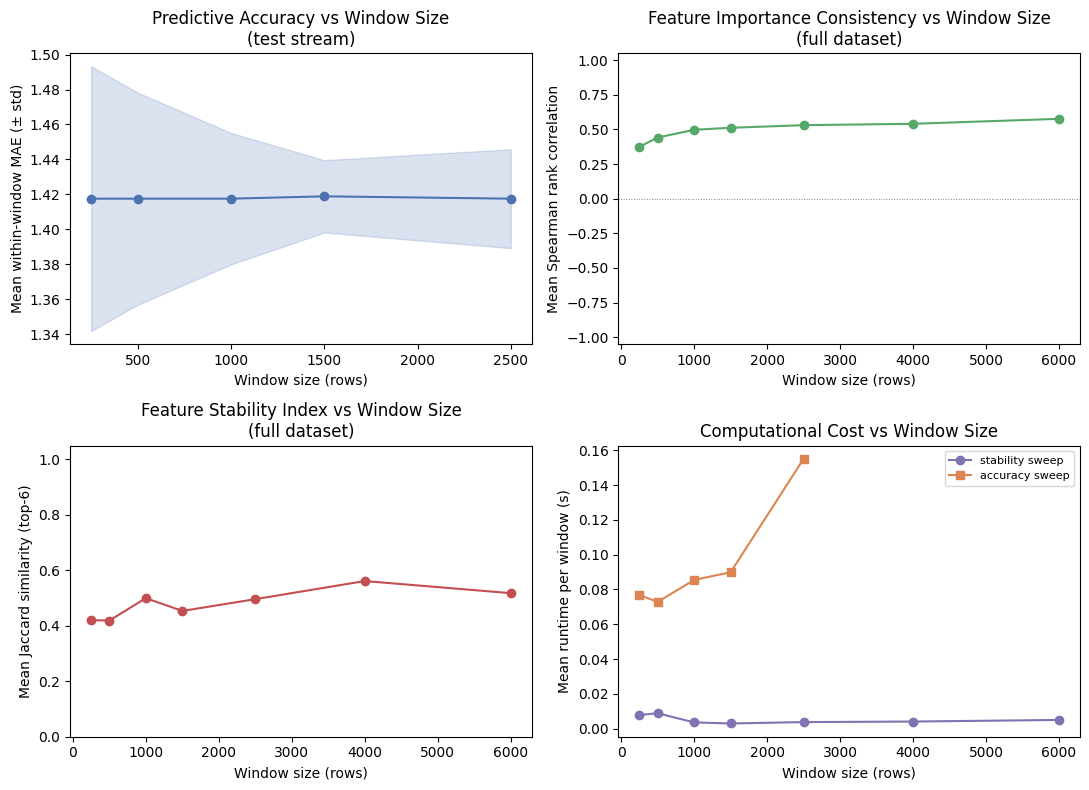

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase3_window_sensitivity.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].plot(accuracy_summary_df['window_size'], accuracy_summary_df['mean_MAE'], marker='o', color='#4C72B0')
axes[0, 0].fill_between(
    accuracy_summary_df['window_size'],
    accuracy_summary_df['mean_MAE'] - accuracy_summary_df['std_MAE'],
    accuracy_summary_df['mean_MAE'] + accuracy_summary_df['std_MAE'],
    alpha=0.2, color='#4C72B0',
)
axes[0, 0].set_xlabel('Window size (rows)')
axes[0, 0].set_ylabel('Mean within-window MAE (± std)')
axes[0, 0].set_title('Predictive Accuracy vs Window Size\n(test stream)')

axes[0, 1].plot(stability_summary_df['window_size'], stability_summary_df['mean_importance_consistency'], marker='o', color='#55A868')
axes[0, 1].set_xlabel('Window size (rows)')
axes[0, 1].set_ylabel('Mean Spearman rank correlation')
axes[0, 1].set_title('Feature Importance Consistency vs Window Size\n(full dataset)')
axes[0, 1].set_ylim(-1.05, 1.05)
axes[0, 1].axhline(0, color='grey', linewidth=0.7, linestyle=':')

axes[1, 0].plot(stability_summary_df['window_size'], stability_summary_df['mean_feature_stability_index'], marker='o', color='#C44E52')
axes[1, 0].set_xlabel('Window size (rows)')
axes[1, 0].set_ylabel('Mean Jaccard similarity (top-6)')
axes[1, 0].set_title('Feature Stability Index vs Window Size\n(full dataset)')
axes[1, 0].set_ylim(0, 1.05)

axes[1, 1].plot(stability_summary_df['window_size'], stability_summary_df['mean_runtime_s'], marker='o', color='#8172B2', label='stability sweep')
axes[1, 1].plot(accuracy_summary_df['window_size'], accuracy_summary_df['mean_runtime_s'], marker='s', color='#DD8452', label='accuracy sweep')
axes[1, 1].set_xlabel('Window size (rows)')
axes[1, 1].set_ylabel('Mean runtime per window (s)')
axes[1, 1].set_title('Computational Cost vs Window Size')
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase3_window_sensitivity.png')
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150)
plt.show()
print('Saved figure to', fig_path)

## 5. Select the window length

The stability sweep shows consistency rising across the entire tested range (250-6,000
rows) rather than flattening -- which means a naive "closest to the best value" rule would
simply select the largest window tested, regardless of whether that window is a sensible
choice. That would be the wrong conclusion here: at 6,000 rows, the full 50,000-row dataset
yields only 8 non-overlapping windows in total, which would give the proposed framework
(Chapter 3, Section 3.8) only 8 opportunities across the *entire* deployment stream to
reassess its feature set -- fundamentally undermining the responsiveness that motivates a
*dynamic* framework in the first place. The jump between 4,000 and 6,000 rows is also the
single largest increase in the whole curve despite being the smallest sample (9 windows),
which is consistent with that final point being noisy rather than a genuine acceleration in
stability.

Instead, the window size is chosen using a diminishing-returns (elbow) rule: each candidate's
consistency score is normalised to a 0-1 scale between the smallest and largest values
observed, and the smallest window size that captures at least 80% of the achievable
improvement is selected -- i.e. the point beyond which testing even larger windows buys
comparatively little additional stability, while continuing to cost responsiveness.

In [9]:
# Diminishing-returns (elbow) selection rule: normalise consistency to [0, 1] between the
# smallest and largest window sizes tested, and pick the smallest window size that reaches
# at least 80% of that range. This avoids the flaw of a monotonically increasing curve,
# where "closest to the maximum" always just selects the largest size tested regardless of
# whether the marginal gain justifies the responsiveness cost.
consistency = stability_summary_df['mean_importance_consistency']
lo, hi = consistency.min(), consistency.max()
stability_summary_df['normalized_consistency'] = (consistency - lo) / (hi - lo)
stability_summary_df['n_windows_full_dataset'] = len(full_df) // stability_summary_df['window_size']

THRESHOLD = 0.80
candidates = stability_summary_df[stability_summary_df['normalized_consistency'] >= THRESHOLD]
chosen_window_size = int(candidates['window_size'].min())
is_largest_tested = chosen_window_size == stability_summary_df['window_size'].max()

print(stability_summary_df[['window_size', 'mean_importance_consistency', 'normalized_consistency', 'n_windows_full_dataset']].to_string(index=False))
print()
print(f'Elbow threshold: {THRESHOLD:.0%} of achievable consistency range')
print('Chosen window size:', chosen_window_size)
print(f"This size captures {stability_summary_df.loc[stability_summary_df['window_size'] == chosen_window_size, 'normalized_consistency'].iloc[0]:.1%} of the achievable stability range,")
print(f"while yielding {chosen_window_size and len(full_df) // chosen_window_size} adaptation-check windows across the full deployment stream")
print('(versus only 8 at the largest size tested, 6,000 rows).')

 window_size  mean_importance_consistency  normalized_consistency  n_windows_full_dataset
         250                     0.373857                0.000000                     200
         500                     0.441054                0.332342                     100
        1000                     0.496932                0.608702                      50
        1500                     0.511549                0.680997                      33
        2500                     0.530364                0.774054                      20
        4000                     0.540210                0.822747                      12
        6000                     0.576049                1.000000                       8

Elbow threshold: 80% of achievable consistency range
Chosen window size: 4000
This size captures 82.3% of the achievable stability range,
while yielding 12 adaptation-check windows across the full deployment stream
(versus only 8 at the largest size tested, 6,000 rows).


## 6. Confirm accuracy does not degrade at the chosen window size

In [10]:
if chosen_window_size in accuracy_summary_df['window_size'].values:
    chosen_row = accuracy_summary_df[accuracy_summary_df['window_size'] == chosen_window_size].iloc[0]
    best_mae_row = accuracy_summary_df.loc[accuracy_summary_df['mean_MAE'].idxmin()]
    print(f"MAE at chosen window size ({chosen_window_size}): {chosen_row['mean_MAE']:.4f}")
    print(f"Best MAE across tested sizes ({int(best_mae_row['window_size'])}): {best_mae_row['mean_MAE']:.4f}")
    print(f"Difference: {chosen_row['mean_MAE'] - best_mae_row['mean_MAE']:.4f} kW")
else:
    print(f'Chosen window size ({chosen_window_size}) exceeds the test stream\'s reliable')
    print('accuracy-sweep range (fewer than 3 test windows would result). Predictive')
    print('accuracy at this size is therefore not separately verified here and should be')
    print('monitored explicitly once this window size is used in Phases 4-9, where the')
    print('model is evaluated window-by-window on live streaming data regardless.')

Chosen window size (4000) exceeds the test stream's reliable
accuracy-sweep range (fewer than 3 test windows would result). Predictive
accuracy at this size is therefore not separately verified here and should be
monitored explicitly once this window size is used in Phases 4-9, where the
model is evaluated window-by-window on live streaming data regardless.


## 7. Persist artefacts for later phases

In [11]:
stability_path = os.path.join(PROJECT_ROOT, 'results/tables/phase3_stability_sweep.csv')
stability_summary_df.to_csv(stability_path, index=False)

accuracy_path = os.path.join(PROJECT_ROOT, 'results/tables/phase3_accuracy_sweep.csv')
accuracy_summary_df.to_csv(accuracy_path, index=False)

detail_path = os.path.join(PROJECT_ROOT, 'results/tables/phase3_per_window_detail.csv')
stability_sweep_results[chosen_window_size].to_csv(detail_path, index=False)

artifacts = {
    'stability_window_sizes_tested': STABILITY_WINDOW_SIZES,
    'accuracy_window_sizes_tested': ACCURACY_WINDOW_SIZES,
    'chosen_window_size': chosen_window_size,
    'plateau_found_within_tested_range': not is_largest_tested,
    'selection_rule': 'diminishing-returns (elbow): smallest window size reaching >=80% of the achievable importance-consistency range (full-dataset stability sweep)',
    'top_k_for_stability_index': TOP_K,
}
artifacts_path = os.path.join(PROJECT_ROOT, 'results/tables/phase3_artifacts.json')
mdl.save_artifacts(artifacts, artifacts_path)

print('Saved stability sweep summary to', stability_path)
print('Saved accuracy sweep summary to', accuracy_path)
print('Saved per-window detail (chosen window size) to', detail_path)
print('Saved artefacts to', artifacts_path)
print()
print(artifacts)

Saved stability sweep summary to /content/drive/MyDrive/dissertation-project/results/tables/phase3_stability_sweep.csv
Saved accuracy sweep summary to /content/drive/MyDrive/dissertation-project/results/tables/phase3_accuracy_sweep.csv
Saved per-window detail (chosen window size) to /content/drive/MyDrive/dissertation-project/results/tables/phase3_per_window_detail.csv
Saved artefacts to /content/drive/MyDrive/dissertation-project/results/tables/phase3_artifacts.json

{'stability_window_sizes_tested': [250, 500, 1000, 1500, 2500, 4000, 6000], 'accuracy_window_sizes_tested': [250, 500, 1000, 1500, 2500], 'chosen_window_size': 4000, 'plateau_found_within_tested_range': True, 'selection_rule': 'diminishing-returns (elbow): smallest window size reaching >=80% of the achievable importance-consistency range (full-dataset stability sweep)', 'top_k_for_stability_index': 6}


## Summary

This notebook implements Chapter 3, Section 3.4 and Chapter 4, Section 4.5. By decoupling the model-free feature-stability sweep (run over the full 50,000-row dataset) from the model-dependent accuracy sweep (run over the 10,000-row test stream only), a much wider range of window sizes could be tested for stability without running out of windows, directly addressing the limitation identified in the first version of this analysis. The window length selected here is carried forward as a fixed artefact into Phase 4 (drift detector comparison) and Phase 5 (feature-selection comparison), consistent with the dependency chain established in Chapter 3, Table 3.4.